In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, event, text
from sqlalchemy.engine import URL

ROOT = r'D:\Bluestock work\bluestock-fintech-analysis1'
PROCESSED_DIR = os.path.join(ROOT, 'data', 'processed')
REPORTS_DIR = os.path.join(ROOT, 'reports')
DB_PATH = os.path.join(PROCESSED_DIR, 'bluestock_dw.db')

engine = create_engine(URL.create('sqlite', database=DB_PATH))

@event.listens_for(engine, 'connect')
def turn_on_foreign_keys(dbapi_connection, connection_record):
    cursor = dbapi_connection.cursor()
    cursor.execute('PRAGMA foreign_keys = ON')
    cursor.close()

In [3]:
returns = pd.read_sql_query("""
SELECT r.amfi_code, d.full_date, r.daily_return, r.days_since_prev
FROM fact_daily_return AS r
JOIN dim_date AS d ON d.date_key = r.date_key
ORDER BY r.amfi_code, r.date_key
""", engine)

returns['date'] = pd.to_datetime(returns['full_date'])

print(returns.shape)
print('Funds:', returns['amfi_code'].nunique())
print(returns['date'].min().date(), 'to', returns['date'].max().date())

(45960, 5)
Funds: 40
2022-01-04 to 2026-05-29


In [4]:
RF_ANNUAL = 0.065
TRADING_DAYS = 252
RF_DAILY = RF_ANNUAL / TRADING_DAYS

print('Daily risk-free rate (%):', round(RF_DAILY * 100, 5))

span = returns.groupby('amfi_code')['date'].agg(['min', 'max', 'count'])
span['years'] = (span['max'] - span['min']).dt.days / 365.25
span['obs_per_year'] = span['count'] / span['years']

print(span['obs_per_year'].describe().round(1))

Daily risk-free rate (%): 0.02579
count     40.0
mean     261.3
std        0.0
min      261.3
25%      261.3
50%      261.3
75%      261.3
max      261.3
Name: obs_per_year, dtype: float64


In [5]:
END_DATE = returns['date'].max()
first_date = returns.groupby('amfi_code')['date'].min()

COMMON_START = first_date.max()
years_common = (END_DATE - COMMON_START).days / 365.25

print('Common window:', COMMON_START.date(), 'to', END_DATE.date(), '| years:', round(years_common, 2))
print('Fund that starts last:', first_date.idxmax())

windows = {
    'common': returns[returns['date'] >= COMMON_START],
    'full': returns,
}

print(windows['common'].groupby('amfi_code').size().describe().round(0))

Common window: 2022-01-04 to 2026-05-29 | years: 4.4
Fund that starts last: 100016
count      40.0
mean     1149.0
std         0.0
min      1149.0
25%      1149.0
50%      1149.0
75%      1149.0
max      1149.0
dtype: float64


In [6]:
def build_blocks(window):
    return window.groupby('amfi_code')['daily_return'].agg(
        days='count',
        mean_daily='mean',
        std_daily='std',
        down_days=lambda s: (s < 0).sum(),
        down_std=lambda s: s[s < 0].std(),
        down_dev=lambda s: np.sqrt((np.minimum(s, 0) ** 2).mean()),
    )


blocks = {}
for name, window in windows.items():
    blocks[name] = build_blocks(window)

(blocks['common'] * [1, 100, 100, 1, 100, 100]).round(3).head(10)

,days,mean_daily,std_daily,down_days,down_std,down_dev
amfi_code,,,,,,
100016,1149,0.014,0.916,579,0.526,0.629
100025,1149,0.017,0.246,549,0.148,0.164
100033,1149,0.108,1.193,538,0.713,0.785
101206,1149,0.085,0.918,539,0.524,0.596
101207,1149,0.042,1.625,568,0.956,1.119
101208,1149,0.024,0.032,261,0.015,0.011
102885,1149,0.067,0.809,537,0.460,0.530
102886,1149,0.011,1.142,559,0.677,0.805
102887,1149,0.065,0.993,556,0.565,0.654


In [7]:
def add_ratios(table):
    out = table.copy()
    root = np.sqrt(TRADING_DAYS)
    excess = out['mean_daily'] - RF_DAILY

    out['sharpe'] = excess / out['std_daily'] * root
    out['sortino_task'] = excess / out['down_std'] * root
    out['sortino_textbook'] = excess / out['down_dev'] * root
    out['ann_return_pct'] = out['mean_daily'] * TRADING_DAYS * 100
    out['ann_vol_pct'] = out['std_daily'] * root * 100

    return out.replace([np.inf, -np.inf], np.nan)


summaries = {}
for name in blocks:
    summaries[name] = add_ratios(blocks[name])

ratios = ['sharpe', 'sortino_task', 'sortino_textbook']
print(summaries['common'][ratios].describe().round(2))
print()
print('Empty values:')
print(summaries['common'][ratios].isnull().sum())

       sharpe  sortino_task  sortino_textbook
count   40.00         40.00             40.00
mean     0.54          0.92              0.81
std      0.57          1.01              0.96
min     -0.82         -1.68             -2.28
25%      0.06          0.11              0.09
50%      0.65          1.12              1.00
75%      1.01          1.73              1.56
max      1.45          2.39              2.23

Empty values:
sharpe              0
sortino_task        0
sortino_textbook    0
dtype: int64


In [ ]:
# validating 

c = summaries['common']

# Check A
code = int(c.index[0])
one = pd.read_sql_query(text("""
    SELECT r.daily_return
    FROM fact_daily_return AS r
    JOIN dim_date AS d ON d.date_key = r.date_key
    WHERE r.amfi_code = :code AND d.full_date >= :start
"""), engine, params={'code': code, 'start': COMMON_START.strftime('%Y-%m-%d')})['daily_return'].to_numpy()

excess_mean = one.mean() - RF_DAILY
sharpe_hand = excess_mean / one.std(ddof=1) * np.sqrt(252)
sortino_hand = excess_mean / one[one < 0].std(ddof=1) * np.sqrt(252)

print('A. Fund', code)
print('   Sharpe  by hand:', round(sharpe_hand, 4), '| in the table:', round(c.loc[code, 'sharpe'], 4))
print('   Sortino by hand:', round(sortino_hand, 4), '| in the table:', round(c.loc[code, 'sortino_task'], 4))
print('   Same values:', np.isclose(sharpe_hand, c.loc[code, 'sharpe']) and np.isclose(sortino_hand, c.loc[code, 'sortino_task']))

# Check B
valid = c.dropna(subset=['sharpe'])
print('B. Sign of Sharpe follows the excess return:',
      bool(((valid['mean_daily'] > RF_DAILY) == (valid['sharpe'] > 0)).all()))

A. Fund 100016
   Sharpe  by hand: -0.2015 | in the table: -0.2015
   Sortino by hand: -0.351 | in the table: -0.351
   Same values: True
B. Sign of Sharpe follows the excess return: True


In [ ]:
# ranking all 40 funds

funds = pd.read_sql_query(
    'SELECT amfi_code, scheme_name, fund_house, category, plan FROM dim_fund', engine)

rank_table = summaries['common'].reset_index().merge(funds, on='amfi_code', how='left')

rank_table['rank_sharpe'] = rank_table['sharpe'].rank(ascending=False, method='min')
rank_table['rank_sortino_task'] = rank_table['sortino_task'].rank(ascending=False, method='min')
rank_table['rank_sortino_textbook'] = rank_table['sortino_textbook'].rank(ascending=False, method='min')
rank_table['rank_sharpe_in_category'] = (
    rank_table.groupby('category')['sharpe'].rank(ascending=False, method='min'))
rank_table['rank_change'] = rank_table['rank_sharpe'] - rank_table['rank_sortino_task']
rank_table['is_idcw'] = rank_table['scheme_name'].str.contains('IDCW|Dividend', case=False, na=False)

show_cols = ['rank_sharpe', 'scheme_name', 'category', 'plan', 'ann_return_pct', 'ann_vol_pct',
             'sharpe', 'sortino_task', 'sortino_textbook',
             'rank_sortino_task', 'rank_sortino_textbook', 'rank_change',
             'rank_sharpe_in_category', 'is_idcw']

ranking = rank_table.sort_values('rank_sharpe')[show_cols].round(2)

print('IDCW funds:', int(rank_table['is_idcw'].sum()))
print(ranking.to_string(index=False))

IDCW funds: 0
 rank_sharpe                                           scheme_name category    plan  ann_return_pct  ann_vol_pct  sharpe  sortino_task  sortino_textbook  rank_sortino_task  rank_sortino_textbook  rank_change  rank_sharpe_in_category  is_idcw
         1.0         Mirae Asset Large Cap Fund - Regular - Growth   Equity Regular           27.06        14.19    1.45          2.39              2.23                1.0                    1.0          0.0                      1.0    False
         2.0                Kotak Flexicap Fund - Regular - Growth   Equity Regular           27.26        15.89    1.31          2.36              2.06                2.0                    2.0          0.0                      2.0    False
         3.0         Mirae Asset Tax Saver Fund - Regular - Growth   Equity Regular           28.33        17.67    1.23          2.15              1.91                3.0                    3.0          0.0                      3.0    False
         4.0      

In [10]:
full = summaries['full'][['days', 'sharpe', 'sortino_task']].add_suffix('_full')
compare = rank_table.merge(full, left_on='amfi_code', right_index=True, how='left')

source = pd.read_sql_query(
    'SELECT amfi_code, sharpe_ratio AS sharpe_source, sortino_ratio AS sortino_source FROM fact_performance',
    engine)
compare = compare.merge(source, on='amfi_code', how='left')

rho_window = compare['sharpe'].corr(compare['sharpe_full'], method='spearman')
rho_sharpe_source = compare['sharpe'].corr(compare['sharpe_source'], method='spearman')
rho_sortino_task_source = compare['sortino_task'].corr(compare['sortino_source'], method='spearman')
rho_sortino_text_source = compare['sortino_textbook'].corr(compare['sortino_source'], method='spearman')

print('Sharpe: common window vs full history:', round(rho_window, 2))
print('Sharpe vs source:', round(rho_sharpe_source, 2))
print('Sortino (task version) vs source:', round(rho_sortino_task_source, 2))
print('Sortino (textbook version) vs source:', round(rho_sortino_text_source, 2))
print()
print('Mean Sharpe  | mine:', round(compare['sharpe'].mean(), 2), '| source:', round(compare['sharpe_source'].mean(), 2))
print('Mean Sortino | mine:', round(compare['sortino_task'].mean(), 2), '| source:', round(compare['sortino_source'].mean(), 2))

Sharpe: common window vs full history: 1.0
Sharpe vs source: -0.22
Sortino (task version) vs source: -0.33
Sortino (textbook version) vs source: -0.29

Mean Sharpe  | mine: 0.54 | source: 1.36
Mean Sortino | mine: 0.92 | source: 2.08


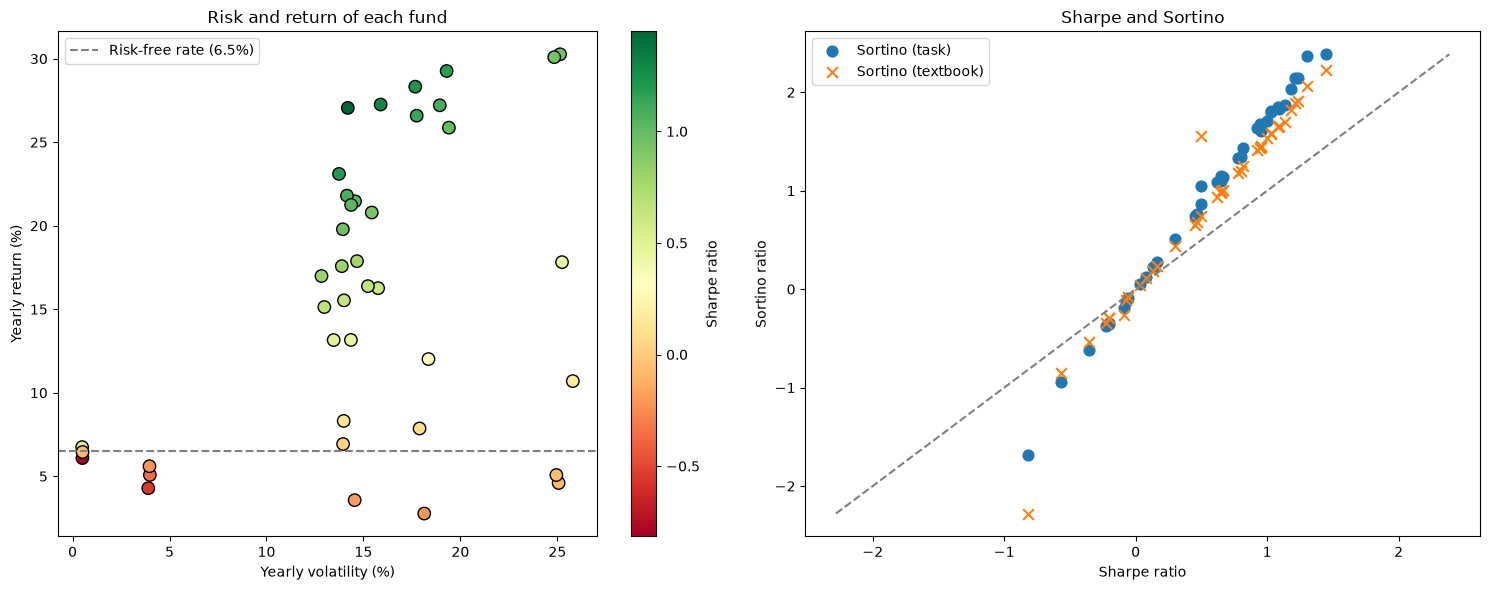

In [11]:
c = rank_table

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sc = axes[0].scatter(c['ann_vol_pct'], c['ann_return_pct'], c=c['sharpe'],
                     cmap='RdYlGn', s=80, edgecolor='black')
axes[0].axhline(RF_ANNUAL * 100, color='gray', linestyle='--', label='Risk-free rate (6.5%)')
axes[0].set_xlabel('Yearly volatility (%)')
axes[0].set_ylabel('Yearly return (%)')
axes[0].set_title('Risk and return of each fund')
axes[0].legend()
fig.colorbar(sc, ax=axes[0], label='Sharpe ratio')

axes[1].scatter(c['sharpe'], c['sortino_task'], label='Sortino (task)', s=60)
axes[1].scatter(c['sharpe'], c['sortino_textbook'], label='Sortino (textbook)', s=60, marker='x')
low = min(c['sharpe'].min(), c['sortino_task'].min(), c['sortino_textbook'].min())
high = max(c['sharpe'].max(), c['sortino_task'].max(), c['sortino_textbook'].max())
axes[1].plot([low, high], [low, high], color='gray', linestyle='--')
axes[1].set_xlabel('Sharpe ratio')
axes[1].set_ylabel('Sortino ratio')
axes[1].set_title('Sharpe and Sortino')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'sharpe_sortino_charts.png'))
plt.show()

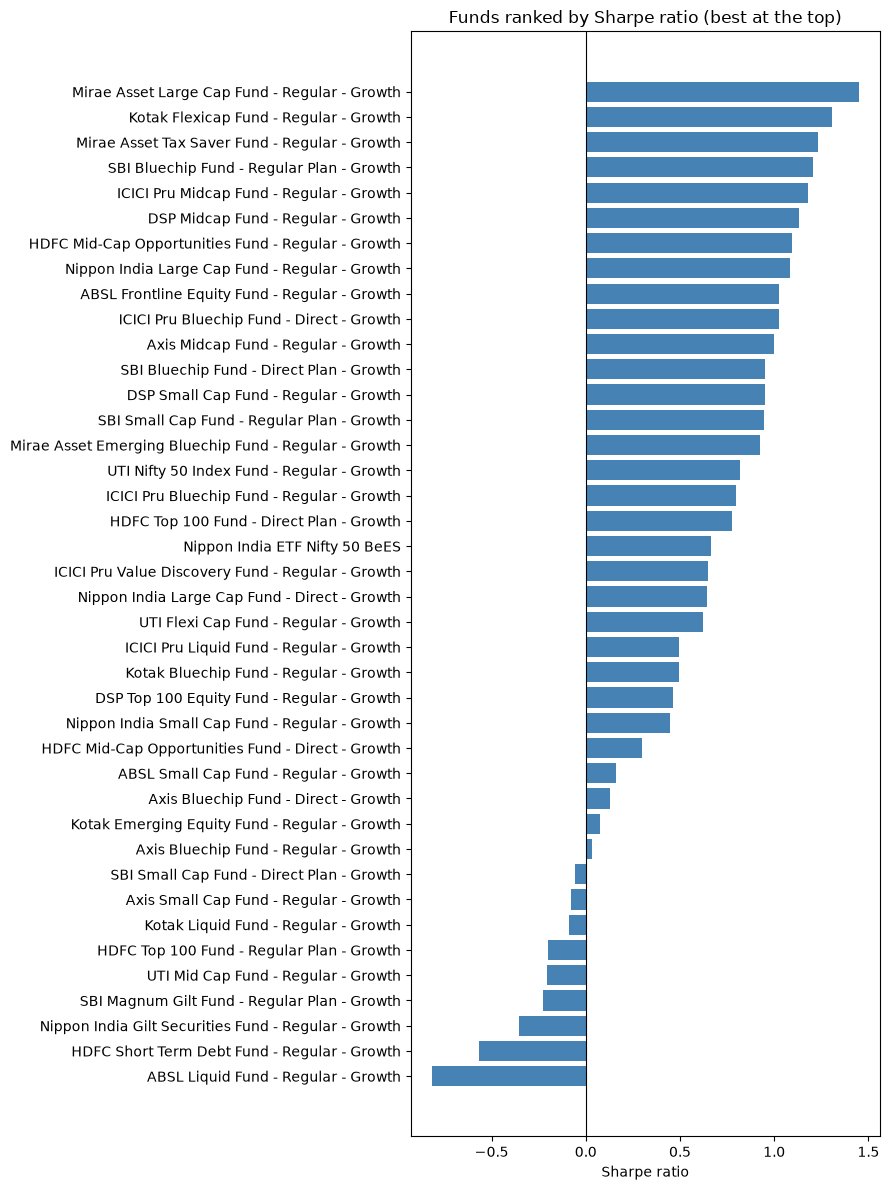

In [12]:
bars = rank_table.sort_values('sharpe')

plt.figure(figsize=(9, 12))
plt.barh(bars['scheme_name'], bars['sharpe'], color='steelblue')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Sharpe ratio')
plt.title('Funds ranked by Sharpe ratio (best at the top)')
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'sharpe_ranking.png'))
plt.show()

In [14]:
out_cols = ['amfi_code', 'scheme_name', 'fund_house', 'category', 'plan', 'is_idcw', 'days',
            'ann_return_pct', 'ann_vol_pct', 'sharpe', 'sortino_task', 'sortino_textbook',
            'rank_sharpe', 'rank_sortino_task', 'rank_sortino_textbook',
            'rank_sharpe_in_category', 'rank_change']

rank_table.sort_values('rank_sharpe')[out_cols].round(4).to_csv(
    os.path.join(PROCESSED_DIR, 'fund_risk_adjusted_returns.csv'), index=False)

best = rank_table.nsmallest(3, 'rank_sharpe')['scheme_name'].tolist()
worst = rank_table.nlargest(3, 'rank_sharpe')['scheme_name'].tolist()

lines = [
    '# Sharpe and Sortino summary',
    '',
    '- Sharpe = (mean daily return - daily Rf) / std of daily returns x sqrt(252).',
    f'- Rf = {RF_ANNUAL * 100:.1f}% a year (RBI repo rate proxy). Daily Rf = Rf / {TRADING_DAYS} = {RF_DAILY * 100:.5f}%.',
    f'- Common window for all funds: {COMMON_START.date()} to {END_DATE.date()} ({years_common:.2f} years).',
    f'- Funds ranked: {len(rank_table)}. NAV days a year in the data: {span["obs_per_year"].mean():.0f}.',
    '- Sortino (task version) uses the standard deviation of the negative days only.',
    '- Sortino (textbook version) uses the downside deviation over all days, with a target of 0.',
    f'- Best 3 by Sharpe: {best}.',
    f'- Worst 3 by Sharpe: {worst}.',
    f'- Funds with a negative Sharpe ratio: {int((rank_table["sharpe"] < 0).sum())}.',
    f'- IDCW funds (payouts look like losses): {int(rank_table["is_idcw"].sum())}.',
    f'- Rank agreement (Spearman): common vs full history {rho_window:.2f}; Sharpe vs source {rho_sharpe_source:.2f}; Sortino task vs source {rho_sortino_task_source:.2f}; Sortino textbook vs source {rho_sortino_text_source:.2f}.',
    '- Checks passed: one fund recomputed by hand, sign of Sharpe follows the excess return.',
    '',
    '## Assumptions to confirm',
    '- Rf is fixed at 6.5% for the whole period.',
    '- 252 trading days a year.',
    '- The ranking uses the common window, so all funds are compared on the same dates.',
    '- Which Sortino version to use: the task version or the textbook version.',
    '- Funds of different categories (equity, debt, liquid) are not directly comparable. See rank_sharpe_in_category.',
]

summary_text = '\n'.join(lines)

with open(os.path.join(REPORTS_DIR, 'sharpe_sortino_summary.md'), 'w', encoding='utf-8') as f:
    f.write(summary_text)

print(summary_text)

# Sharpe and Sortino summary

- Sharpe = (mean daily return - daily Rf) / std of daily returns x sqrt(252).
- Rf = 6.5% a year (RBI repo rate proxy). Daily Rf = Rf / 252 = 0.02579%.
- Common window for all funds: 2022-01-04 to 2026-05-29 (4.40 years).
- Funds ranked: 40. NAV days a year in the data: 261.
- Sortino (task version) uses the standard deviation of the negative days only.
- Sortino (textbook version) uses the downside deviation over all days, with a target of 0.
- Best 3 by Sharpe: ['Mirae Asset Large Cap Fund - Regular - Growth', 'Kotak Flexicap Fund - Regular - Growth', 'Mirae Asset Tax Saver Fund - Regular - Growth'].
- Worst 3 by Sharpe: ['ABSL Liquid Fund - Regular - Growth', 'HDFC Short Term Debt Fund - Regular - Growth', 'Nippon India Gilt Securities Fund - Regular - Growth'].
- Funds with a negative Sharpe ratio: 9.
- IDCW funds (payouts look like losses): 0.
- Rank agreement (Spearman): common vs full history 1.00; Sharpe vs source -0.22; Sortino task vs source -0.3